# Path A, P7 — target 10: crossing time (Oct 26, 2026)

Runs: `load_runs("behavior", roles={"train", "val"}, keep_bot=False, keep_incomplete=False)` (the runs of targets 8 (b) and 9). Positions: sign-corrected, k = round(10 s). End bands: k >= 9 and k <= −9; both directions count. CC runs first go through `lab_log` (tick 0.1 s); lab data (EL, CL) are used as logged. Check: CC on its raw rows.

- **Crossing** (`crossings.crossing_events`, per human player): starts at the first step out of an end band; stops at the first of **complete** (first step into the opposite band), **aborted** (a reversal away from the target, `detect_events` m = 2; probes allowed), **returned** (a step back into the band it started from; the next step out starts a new crossing), **unfinished** (the round ends first).
- **has_jump:** a raw row with |Δk| >= 4 inside the crossing. Only complete crossings without a jump are used for 10a–c.
- **Pause:** a gap > 0.3 s between the player's consecutive step rows inside the crossing; the other gaps are moving time. Steps = sum of |Δk| over the rows that close a moving gap.
- **10a** crossing time median, Q1, Q3 (s). **10b** pace = all steps / all moving time (steps/s). **10c** pause share = all pause time / all crossing time (%), and % of crossings with >= 1 pause.
- **Descriptive:** crossings started, by status, with a jump; jumps (raw rows, |Δk| >= 4, human players, whole rounds) per human player-minute (`labclock.exposure`).
- **95% CIs:** group bootstrap (log files, 10,000 resamples, seed 573).

Function: `targets.crossing_time_table` (`src/slider/targets.py`). Saved: `results/tables/target10_crossing_time.csv`, `results/figures/target10_crossing_time.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slider import config
from slider import slider_logs as sl
from slider import targets
from slider.labclock import CELLS

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

runs, table = sl.load_runs("behavior", roles={"train", "val"}, keep_bot=False, keep_incomplete=False)
summary, crossings = targets.crossing_time_table(runs)
summary_raw, crossings_raw = targets.crossing_time_table(runs, lab_clock_cc=False)
summary_02 = targets.crossing_time_table(runs, pause=0.2)[0]
summary_05 = targets.crossing_time_table(runs, pause=0.5)[0]

In [2]:
COUNTS = ["started"] + targets.STATUSES + ["with_jump", "used", "jumps", "player_min"]


def wide(s):
    """One row per stat, one column per cell: counts as numbers, stats as "value [lo, hi]"."""
    s = s.assign(cell=[f"{v:.0f}" if stat in COUNTS[:-1] else f"{v:.1f}" if stat == "player_min"
                       else f"{v:.3f} [{lo:.3f}, {hi:.3f}]" for stat, v, lo, hi in
                       zip(s["stat"], s["value"], s["ci_lo"], s["ci_hi"])])
    return s.pivot_table(index="stat", columns=["topology", "dataset"], values="cell", aggfunc="first", sort=False)


def values(s):
    """Point values: one row per stat, one column per cell."""
    return s.pivot_table(index="stat", columns=["topology", "dataset"], values="value", sort=False)

## Per cell (CC on the lab clock, pause 0.3 s)

In [3]:
wide(summary)

topology                              Hierarchy                                                                       Full                                              Star
dataset                                      EL                       CL                       CC                       CL                       CC                       CC
stat                                                                                                                                                                        
started                                    1044                      798                      732                     1766                      933                      446
complete                                    667                      526                      602                     1044                      702                      356
aborted                                     368                      253                      127                      689                      213                       86
returned                                      9                       15                        2                       24                       18                        4
unfinished                                    0                        4                        1                        9                        0                        0
with_jump                                     1                        1                        0                        0                        1                        1
used                                        666                      525                      602                     1044                      702                      356
jumps                                         1                        1                        0                        0                        2                        2
player_min                                438.8                    424.6                    260.5                    745.2                    241.2                    181.7
crossing_time_median_s     1.800 [1.700, 2.005]     1.800 [1.700, 2.600]     0.600 [0.600, 0.700]     3.300 [2.500, 5.200]     0.600 [0.600, 0.600]     0.600 [0.600, 0.600]
crossing_time_q1_s         1.600 [1.600, 1.700]     1.600 [1.600, 1.700]     0.500 [0.500, 0.600]     1.700 [1.700, 2.000]     0.500 [0.500, 0.600]     0.500 [0.500, 0.600]
crossing_time_q3_s         3.300 [3.000, 3.800]     4.190 [3.000, 8.500]     1.275 [0.600, 2.400]     8.492 [5.125, 8.700]     1.500 [1.349, 2.000]     1.500 [1.175, 1.800]
pace_steps_per_s           8.613 [8.139, 9.137]     8.556 [7.882, 9.148]  17.686 [13.484, 21.904]     7.770 [7.312, 8.201]  16.081 [14.441, 18.159]  16.579 [14.219, 18.970]
pause_share_pct         44.601 [37.823, 51.247]  56.276 [39.136, 73.582]  28.319 [22.656, 34.186]  73.634 [62.944, 83.620]  38.950 [32.789, 45.148]  36.718 [27.839, 46.348]
pct_with_pause          45.045 [40.185, 49.596]  44.952 [36.364, 57.050]  22.757 [15.789, 31.643]  63.697 [55.526, 73.281]  29.630 [23.315, 35.014]  29.494 [24.408, 35.912]
jumps_per_player_min       0.002 [0.000, 0.007]     0.002 [0.000, 0.009]     0.000 [0.000, 0.000]     0.000 [0.000, 0.000]     0.008 [0.000, 0.028]     0.011 [0.000, 0.036]

## Check: CC on its raw rows

In [4]:
lab = summary["dataset"] != "CC"
print("lab cells identical:", summary[lab].reset_index(drop=True).equals(summary_raw[lab].reset_index(drop=True)))
wide(summary_raw[~lab])

lab cells identical: True


topology,Hierarchy,Full,Star
dataset,CC,CC,CC
stat,,,
started,734,939,446
complete,601,702,356
aborted,128,214,86
returned,4,23,4
unfinished,1,0,0
with_jump,0,1,1
used,601,702,356
jumps,0,2,2


In [5]:
print("raw CC minus lab clock (point values, CC cells)")
(values(summary_raw[~lab]) - values(summary[~lab])).round(3)

raw CC minus lab clock (point values, CC cells)


topology,Hierarchy,Full,Star
dataset,CC,CC,CC
stat,,,
started,2.000,6.000,0.000
complete,-1.000,0.000,0.000
aborted,1.000,1.000,0.000
returned,2.000,5.000,0.000
unfinished,0.000,0.000,0.000
with_jump,0.000,0.000,0.000
used,-1.000,0.000,0.000
jumps,0.000,0.000,0.000


## Sensitivity: pause 0.2 s and 0.5 s (CC on the lab clock)

In [6]:
same = [stat for stat in summary["stat"].unique() if stat not in ["pace_steps_per_s", "pause_share_pct", "pct_with_pause"]]
for name, s in [("0.2", summary_02), ("0.5", summary_05)]:
    a, b = summary[summary["stat"].isin(same)], s[s["stat"].isin(same)]
    print(f"pause {name}: counts, crossing times and jump rate identical to pause 0.3:",
          a.reset_index(drop=True).equals(b.reset_index(drop=True)))
stats = ["pace_steps_per_s", "pause_share_pct", "pct_with_pause"]
pd.concat({f"pause {name}": wide(s).loc[stats] for name, s in
           [("0.2", summary_02), ("0.3", summary), ("0.5", summary_05)]})

pause 0.2: counts, crossing times and jump rate identical to pause 0.3: True
pause 0.5: counts, crossing times and jump rate identical to pause 0.3: True


topology                                  Hierarchy                                                                       Full                                              Star
dataset                                          EL                       CL                       CC                       CL                       CC                       CC
          stat                                                                                                                                                                  
pause 0.2 pace_steps_per_s    9.615 [9.124, 10.090]     9.533 [9.072, 9.973]  20.542 [16.392, 23.941]     9.087 [8.664, 9.489]  19.052 [17.391, 20.906]  19.978 [17.838, 22.053]
          pause_share_pct   53.813 [46.933, 60.066]  63.437 [48.319, 78.193]  40.213 [30.362, 48.709]  79.745 [70.894, 87.654]  50.505 [43.513, 56.825]  49.795 [40.908, 57.488]
          pct_with_pause    50.150 [44.741, 55.460]  49.333 [41.168, 60.573]  27.243 [18.045, 40.362]  65.421 [57.321, 74.797]  32.194 [25.160, 38.305]  33.708 [27.912, 40.984]
pause 0.3 pace_steps_per_s     8.613 [8.139, 9.137]     8.556 [7.882, 9.148]  17.686 [13.484, 21.904]     7.770 [7.312, 8.201]  16.081 [14.441, 18.159]  16.579 [14.219, 18.970]
          pause_share_pct   44.601 [37.823, 51.247]  56.276 [39.136, 73.582]  28.319 [22.656, 34.186]  73.634 [62.944, 83.620]  38.950 [32.789, 45.148]  36.718 [27.839, 46.348]
          pct_with_pause    45.045 [40.185, 49.596]  44.952 [36.364, 57.050]  22.757 [15.789, 31.643]  63.697 [55.526, 73.281]  29.630 [23.315, 35.014]  29.494 [24.408, 35.912]
pause 0.5 pace_steps_per_s     7.144 [6.701, 7.698]     5.889 [4.500, 7.139]  15.447 [11.835, 19.410]     4.808 [3.744, 5.852]  13.656 [12.297, 15.538]  13.760 [11.718, 15.852]
          pause_share_pct   26.771 [21.808, 31.706]  24.615 [16.571, 32.314]  15.411 [10.714, 19.939]  43.677 [36.314, 50.012]  25.191 [18.637, 32.310]  20.045 [10.712, 31.091]
          pct_with_pause    26.276 [22.388, 30.572]  26.095 [19.011, 36.911]   10.299 [5.769, 17.510]  44.444 [36.937, 54.250]  14.957 [10.759, 19.328]   11.798 [8.928, 15.193]

## Crossings with no moving time (every gap > 0.3 s), by file

Used crossings only. Most common nonzero |ΔX| per row of the file's human players, for reference.

In [7]:
used = crossings[(crossings["status"] == "complete") & ~crossings["has_jump"].astype(bool)]
none = used[used["moving"] == 0].groupby(["dataset", "file"]).size().rename("no moving time")
step = {}
for run in runs:
    if run["file"] in none.index.get_level_values("file"):
        dx = np.round(np.abs(np.diff(run["X"], axis=0)), 3)
        step.setdefault(run["file"], []).extend(dx[dx > 0])
mode = {f: pd.Series(v).mode().iloc[0] for f, v in step.items()}
none = none.reset_index()
none["used in file"] = [int(np.sum(used["file"] == f)) for f in none["file"]]
none["most common |ΔX|"] = none["file"].map(mode)
none.sort_values("no moving time", ascending=False)

,dataset,file,no moving time,used in file,most common |ΔX|
1,CL,log_Fri Sep 16 165753 EDT 2016.txt,62,64,0.02
2,CL,log_Mon Sep 19 164446 EDT 2016.txt,51,53,0.02
5,CL,log_Wed Sep 21 160602 EDT 2016.txt,50,56,0.02
4,CL,log_Tue Sep 20 142130 EDT 2016.txt,28,31,0.02
3,CL,log_Mon Sep 19 173635 EDT 2016.txt,20,20,0.02
8,CL,log_v09_Fri Sep 23 155758 EDT 2016.txt,5,135,0.10
7,CL,log_v09_Fri Oct 07 162937 EDT 2016.txt,3,122,0.10
10,CL,log_v09_Mon Sep 26 173549 EDT 2016.txt,3,204,0.10
6,CL,log_v09_Fri Oct 07 155453 EDT 2016.txt,2,104,0.10
12,EL,log_v09_Mon Nov 07 175505 EST 2016.txt,2,69,0.10


## Figure

Used crossings (complete, no jump), CC on the lab clock. Top: crossing time (log axis), dashed line = median (10a). Bottom: pace of each crossing (steps / moving time; crossings with no moving time left out), dashed line = pooled pace (10b). Bars are shares of the cell's crossings.

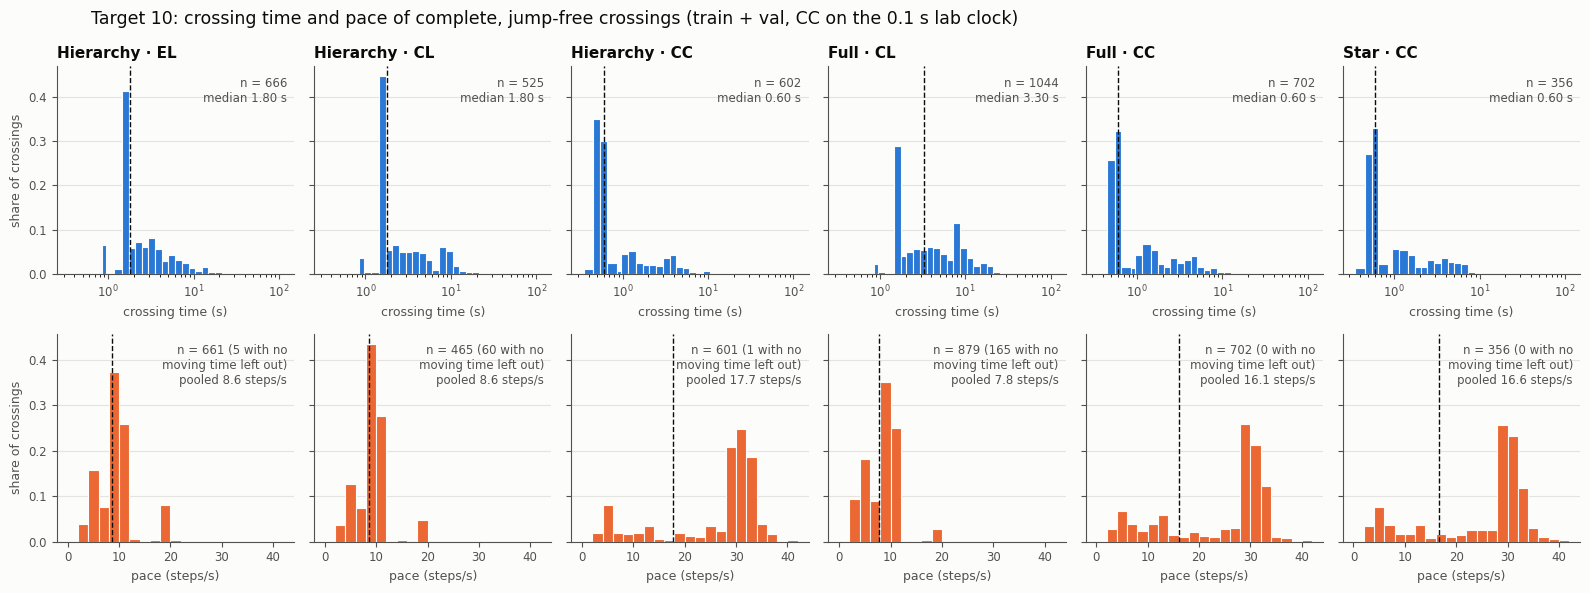

In [8]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
time_bins = np.unique(np.round(np.geomspace(0.3, 150, 36), 1)) - 0.05     # >= 0.1 s wide, edges between 0.1 s values
pace_bins = np.arange(0, 44, 2)
v = values(summary)

fig, axes = plt.subplots(2, 6, figsize=(16, 6), facecolor=SURFACE, sharey="row")
for col, (topology, dataset) in enumerate(CELLS):
    u = used[(used["topology"] == topology) & (used["dataset"] == dataset)]
    pace = (u["steps"] / u["moving"]).replace(np.inf, np.nan).dropna()
    top, bottom = axes[0, col], axes[1, col]
    top.hist(u["duration"], bins=time_bins, weights=np.full(len(u), 1 / len(u)), color=BLUE,
             edgecolor=SURFACE, linewidth=0.8)
    top.set_xscale("log")
    top.axvline(v.loc["crossing_time_median_s", (topology, dataset)], color=INK, linestyle="--", linewidth=1)
    top.set_title(f"{topology} · {dataset}", loc="left", fontsize=11, color=INK, fontweight="bold")
    top.text(0.97, 0.95, f"n = {len(u)}\nmedian {v.loc['crossing_time_median_s', (topology, dataset)]:.2f} s",
             transform=top.transAxes, ha="right", va="top", fontsize=8.5, color=INK_2)
    top.set_xlabel("crossing time (s)", color=INK_2, fontsize=9)
    bottom.hist(pace, bins=pace_bins, weights=np.full(len(pace), 1 / len(pace)), color=ORANGE,
                edgecolor=SURFACE, linewidth=0.8)
    bottom.axvline(v.loc["pace_steps_per_s", (topology, dataset)], color=INK, linestyle="--", linewidth=1)
    bottom.text(0.97, 0.95, f"n = {len(pace)} ({len(u) - len(pace)} with no\nmoving time left out)\n"
                f"pooled {v.loc['pace_steps_per_s', (topology, dataset)]:.1f} steps/s",
                transform=bottom.transAxes, ha="right", va="top", fontsize=8.5, color=INK_2)
    bottom.set_xlabel("pace (steps/s)", color=INK_2, fontsize=9)
    for a in (top, bottom):
        a.set_facecolor(SURFACE)
        a.grid(axis="y", color=GRID, linewidth=0.8)
        a.set_axisbelow(True)
        for side in ("top", "right"):
            a.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            a.spines[side].set_color(INK_2)
        a.tick_params(colors=INK_2, labelsize=8.5)
axes[0, 0].set_ylabel("share of crossings", color=INK_2, fontsize=9)
axes[1, 0].set_ylabel("share of crossings", color=INK_2, fontsize=9)
for a in axes[0]:
    a.set_xlim(0.25, 150)
fig.suptitle("Target 10: crossing time and pace of complete, jump-free crossings (train + val, CC on the 0.1 s lab clock)",
             x=0.06, ha="left", fontsize=12.5, color=INK)
fig.tight_layout()
fig.savefig(config.TARGET10_FIGURE, dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()

## Save

In [9]:
sets = {"target10": summary, "target10_raw_cc": summary_raw, "target10_pause_0.2": summary_02,
        "target10_pause_0.5": summary_05}
out = pd.concat([s.assign(set=name) for name, s in sets.items()])
out = out[["set"] + list(summary.columns)]
out.to_csv(config.TARGET10, index=False)
print(config.TARGET10.name, len(out), "rows;", config.TARGET10_FIGURE.name)

target10_crossing_time.csv 384 rows; target10_crossing_time.png
